# Pareja A — Datos y modelo lineal base

## 1.0 Alcance, problema y objetivo

Este notebook cubre **exclusivamente el eje de trabajo de la pareja A**:

- análisis exploratorio de datos (EDA);
- preparación reproducible y control de *data leakage*;
- regresión logística como modelo lineal base.

No se incluyen aquí Random Forest, ajuste de hiperparámetros del modelo no lineal, curvas ROC comparativas ni pruebas estadísticas entre modelos, porque corresponden a las parejas B y C.

### Contexto

El conjunto **Banknote Authentication** contiene observaciones de billetes descritos por cuatro variables continuas obtenidas a partir de imágenes transformadas mediante wavelets. La etiqueta indica si el billete es genuino (`0`) o falso (`1`). El objetivo de esta parte es construir una línea base sólida y explicable que permita saber qué tan bien puede separar las clases un modelo lineal.

![Billete de referencia](https://upload.wikimedia.org/wikipedia/commons/1/1d/United_States_one_dollar_bill%2C_reverse.jpg?utm_source=es.wikipedia.org&utm_campaign=index&utm_content=original)

*Imagen ilustrativa: reverso de un billete de un dólar estadounidense. Fuente: Wikimedia Commons.*

# 1.1 Pregunta de investigación y métrica principal

### Pregunta de investigación del proyecto

**¿Cuál de los dos modelos de clasificación —la regresión logística como modelo lineal base o el modelo no lineal— identifica mejor los billetes falsos, manteniendo un protocolo de evaluación estratificado, reproducible y libre de fuga de información?**

Esta es la pregunta general del proyecto completo: no busca evaluar la regresión logística de forma aislada, sino comparar dos familias de modelos bajo condiciones equivalentes. Ambos modelos deben utilizar las mismas observaciones, las mismas particiones estratificadas y la misma métrica principal, para que la diferencia observada pueda atribuirse al comportamiento de los algoritmos y no a una ventaja accidental del procedimiento experimental.

### Contribución específica de la pareja A

La pareja A construye la referencia lineal del experimento: documenta el dataset, realiza el EDA, prepara las variables sin *data leakage* y entrena la regresión logística. La pareja B desarrolla el modelo no lineal y la pareja C integra la comparación de resultados, el análisis de errores y la prueba estadística.

### Métrica principal: recall de la clase falsa

La métrica principal común para comparar los dos modelos será el **recall (sensibilidad) de la clase `1`, billete falso**:

$$\text{Recall}_{falso} = \frac{TP}{TP + FN}.$$

- `TP` (*true positive*): billetes falsos correctamente detectados.
- `FN` (*false negative*): billetes falsos clasificados como genuinos.

Se selecciona esta métrica porque el falso negativo es el error operacional más riesgoso: permitir que un billete falso pase como genuino puede producir una pérdida económica directa. Un recall alto significa que el modelo detecta una mayor proporción de las falsificaciones existentes. Precision, F1 y accuracy se reportarán como métricas complementarias, ya que un sistema real también debe controlar cuántos billetes genuinos son marcados erróneamente como falsos y cuál es su rendimiento global.

> La conclusión final sobre qué modelo es preferible debe considerar el recall, la variabilidad entre pliegues, la matriz de confusión, los costos de FP/FN y la prueba estadística de la comparación. Esta celda define el criterio común; no anticipa cuál modelo ganará.

# 1.2 Preparación del entorno y criterios visuales

Se utiliza únicamente Matplotlib para las figuras. Las paletas `Blues` y `RdPu` pertenecen a Matplotlib y producen un contraste limpio: azul para la clase genuina y coral para la clase falsa. Los mismos colores se reutilizan en todos los gráficos para evitar interpretaciones visuales inconsistentes.

El `random_state=42` fija las decisiones aleatorias del experimento y hace que otra persona pueda reproducir las mismas particiones y resultados.

Cada figura se guarda automáticamente en `../report/plots` en formato PNG con 300 DPI y un nombre descriptivo, además de mostrarse en el notebook.

La matriz de dispersión se exporta como `04_matriz_dispersion_por_clase.png`.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ['variance', 'skewness', 'kurtosis', 'entropy']
TARGET = 'is_fake'
RANDOM_STATE = 42
PLOTS_DIR = Path('../report/plots')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Paleta sobria de Matplotlib: azul para genuinos y coral para falsos.
blues = plt.get_cmap('Blues')
corals = plt.get_cmap('RdPu')
COLORS = {0: blues(0.72), 1: corals(0.72)}
CLASS_LABELS = {0: 'Genuino (0)', 1: 'Falso (1)'}

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.dpi': 110,
})

# 1.3 Análisis exploratorio: carga y estructura del dataset

El primer paso del EDA es comprobar que el archivo contiene la estructura que esperamos. Cada fila representa un billete y cada columna una medición o la etiqueta. Las cuatro características son numéricas continuas; la etiqueta es binaria.

- **Varianza (`variance`)**: dispersión de los valores de intensidad de la imagen transformada. Una varianza alta indica mayor variación local.
- **Asimetría (`skewness`)**: mide si la distribución de intensidades se inclina hacia un lado respecto a su centro.
- **Curtosis (`kurtosis`)**: describe el peso de las colas y qué tan apuntada o plana es la distribución.
- **Entropía (`entropy`)**: cuantifica la irregularidad o cantidad de información de la imagen transformada.

Estas variables no son píxeles individuales: son descriptores estadísticos compactos que resumen propiedades de la imagen.

In [122]:
data_path = Path('../data/data_banknote_authentication.txt')
if not data_path.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {data_path.resolve()}')

df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise').astype(int)

print(f'Filas (billetes): {len(df):,}')
print(f'Columnas: {df.shape[1]} ({len(FEATURES)} características + 1 etiqueta)')
display(df.head())

Filas (billetes): 1,372
Columnas: 5 (4 características + 1 etiqueta)


,variance,skewness,kurtosis,entropy,is_fake
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


# 1.4 EDA: calidad de los datos

Antes de calcular métricas o entrenar un modelo se revisa la calidad de la tabla:

- **Valores nulos (`NaN`)**: representan información ausente. Si existieran, habría que decidir si imputarlos o eliminar observaciones; en este trabajo se detiene el flujo para no ocultar el problema.
- **Valores no finitos**: `inf` y `-inf` no son mediciones válidas y pueden romper el escalado o el optimizador.
- **Tipos de datos**: las características deben poder tratarse como números y la etiqueta debe pertenecer exactamente a `{0, 1}`.
- **Duplicados**: se reportan porque pueden hacer que algunas observaciones aparezcan repetidas. No se eliminan automáticamente: una eliminación sin justificación podría quitar información legítima.

In [123]:
expected_classes = {0, 1}
observed_classes = set(df[TARGET].unique())
if observed_classes != expected_classes:
    raise ValueError(f'Las clases esperadas son {expected_classes}, pero se encontraron {observed_classes}.')
if df[FEATURES].isna().any().any():
    raise ValueError('El dataset contiene valores ausentes en las características.')
if not np.isfinite(df[FEATURES].to_numpy()).all():
    raise ValueError('El dataset contiene valores no finitos en las características.')

quality = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'n_unicos': df.nunique(),
})
print(f'Filas duplicadas detectadas: {df.duplicated().sum()}')
display(quality)

Filas duplicadas detectadas: 24


,tipo,nulos,n_unicos
variance,float64,0,1338
skewness,float64,0,1256
kurtosis,float64,0,1270
entropy,float64,0,1156
is_fake,int64,0,2


# 1.5 EDA: estadística descriptiva e interpretación

La tabla descriptiva resume cada característica:

- **count**: número de valores disponibles. Debe coincidir con el número de filas si no hay nulos.
- **mean**: promedio; sirve como referencia del centro, aunque puede verse afectado por valores extremos.
- **std**: desviación estándar muestral; mide cuánto se dispersan los valores alrededor de la media. Una `std` grande implica una escala numérica más amplia.
- **min / max**: extremos observados; ayudan a identificar rangos y posibles valores atípicos.
- **25%, 50%, 75%**: cuartiles. El 50% es la mediana; el intervalo entre 25% y 75% contiene la mitad central de los datos.

La comparación de rangos y desviaciones es especialmente importante para la regresión logística, ya que el modelo utiliza una combinación lineal de las características.

In [124]:
descriptive_stats = df[FEATURES].describe().T
# El rango complementa a std y facilita comparar escalas entre variables.
descriptive_stats['range'] = descriptive_stats['max'] - descriptive_stats['min']
display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,range
variance,1372.0,0.434,2.843,-7.042,-1.773,0.496,2.821,6.825,13.867
skewness,1372.0,1.922,5.869,-13.773,-1.708,2.320,6.815,12.952,26.725
kurtosis,1372.0,1.398,4.310,-5.286,-1.575,0.617,3.179,17.927,23.214
entropy,1372.0,-1.192,2.101,-8.548,-2.413,-0.587,0.395,2.450,10.998


# 1.6 EDA: distribución de la variable objetivo

La distribución de clases indica si el problema está balanceado. Si una clase fuera muy dominante, un modelo podría obtener una exactitud engañosamente alta prediciendo casi siempre la clase mayoritaria. En este dataset las clases están relativamente equilibradas, por lo que accuracy puede ser informativa, aunque también se deben observar precision, recall y F1.

La clase `1` representa billetes falsos y la clase `0` billetes genuinos. Las etiquetas porcentuales dentro de las barras muestran la participación de cada clase en el total.

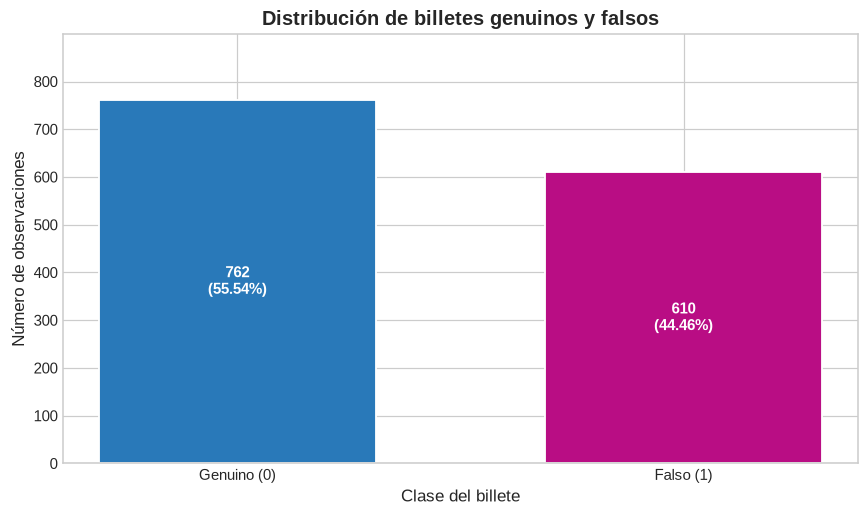

,count,percentage
is_fake,,
Genuino (0),762,55.54
Falso (1),610,44.46


In [125]:
class_counts = df[TARGET].value_counts().sort_index()
class_percentages = class_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(class_counts))
bars = ax.bar(
    x,
    class_counts.to_numpy(),
    color=[COLORS[label] for label in class_counts.index],
    edgecolor='white',
    linewidth=1.2,
    width=0.62,
)
ax.set_xticks(x, [CLASS_LABELS[label] for label in class_counts.index])
ax.set_xlabel('Clase del billete')
ax.set_ylabel('Número de observaciones')
ax.set_title('Distribución de billetes genuinos y falsos')
ax.set_ylim(0, class_counts.max() * 1.18)
for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 0.5,
        f'{count:,}\n({percentage:.2f}%)',
        ha='center', va='center', fontweight='bold', color='white',
    )
plt.tight_layout()
fig.savefig(PLOTS_DIR / '01_distribucion_clases.png', dpi=300, bbox_inches='tight')
plt.show()

display(pd.DataFrame({'count': class_counts, 'percentage': class_percentages.round(2)}).rename(index=CLASS_LABELS))

# 1.7 EDA: distribución de las características

Los histogramas muestran cómo se distribuye cada descriptor y si existe separación visual entre clases. Una separación clara sugiere que esa característica podría aportar información al clasificador; un gran solapamiento indica que esa variable, por sí sola, no basta para decidir.

La densidad normaliza las alturas para que las formas de las distribuciones sean comparables incluso cuando las clases tienen tamaños diferentes. Estas figuras son descriptivas: no prueban por sí solas que una variable cause la etiqueta ni sustituyen la evaluación cruzada.

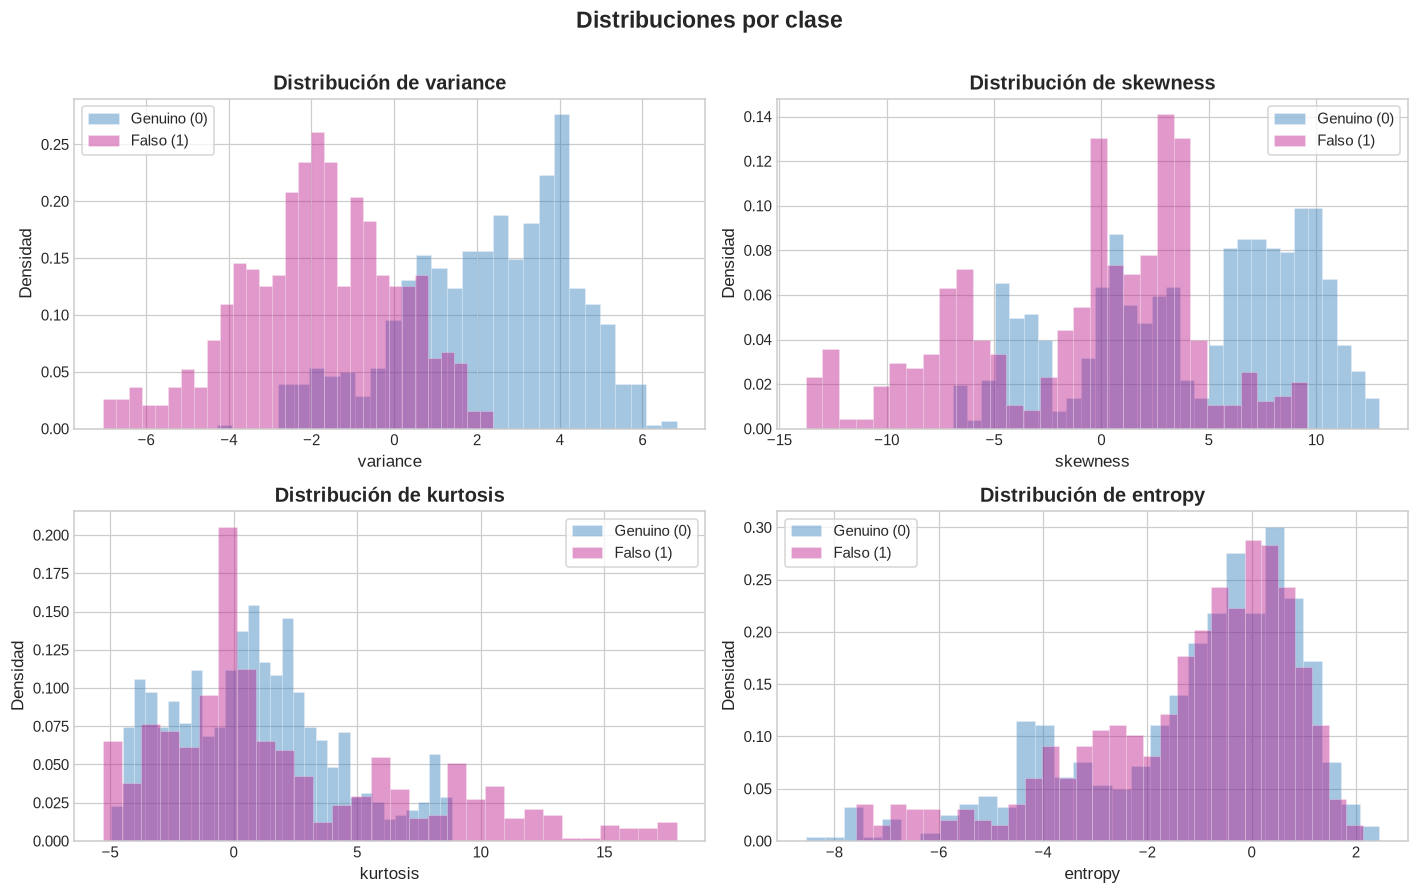

In [126]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, feature in zip(axes.flat, FEATURES):
    for label, color in COLORS.items():
        subset = df.loc[df[TARGET] == label, feature]
        ax.hist(
            subset,
            bins=30,
            density=True,
            alpha=0.42,
            color=color,
            edgecolor='white',
            linewidth=0.35,
            label=CLASS_LABELS[label],
        )
    ax.set_title(f'Distribución de {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Densidad')
    ax.legend(frameon=True)
fig.suptitle('Distribuciones por clase', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '02_distribuciones_caracteristicas.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.8 EDA: matriz de correlación

La correlación de Pearson mide la asociación lineal entre dos variables, con valores entre `-1` y `1`:

- valores cercanos a `1`: relación lineal positiva;
- valores cercanos a `-1`: relación lineal negativa;
- valores cercanos a `0`: poca relación lineal.

La matriz ayuda a detectar predictores redundantes y a entender la estructura del espacio de características. **Correlación no significa causalidad** y una correlación baja no descarta relaciones no lineales. Para la regresión logística, correlaciones muy altas podrían dificultar la interpretación individual de los coeficientes porque varias variables aportarían información similar.

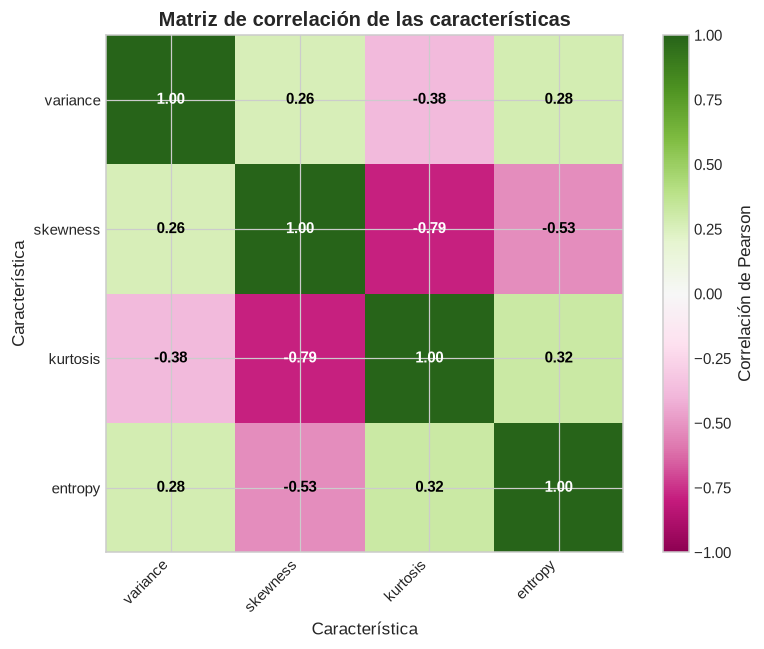

Correlaciones lineales más fuertes entre variables distintas:


abs_correlation
skewness kurtosis         0.786895
         entropy          0.526321
variance kurtosis         0.380850

In [127]:
correlation = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, cmap='PiYG', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha='right')
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_xlabel('Característica')
ax.set_ylabel('Característica')
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        value = correlation.iloc[i, j]
        text_color = 'white' if abs(value) > 0.55 else 'black'
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color=text_color, fontweight='bold')
fig.colorbar(im, ax=ax, label='Correlación de Pearson')
ax.set_title('Matriz de correlación de las características')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '03_matriz_correlacion.png', dpi=300, bbox_inches='tight')
plt.show()

print('Correlaciones lineales más fuertes entre variables distintas:')
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
display(upper.abs().sort_values(ascending=False).head(3).rename('abs_correlation').to_frame())

### Lectura de los resultados observados

En este dataset, la relación lineal más notable es entre **asimetría y curtosis**, con una correlación aproximada de `-0.79`: cuando una aumenta, la otra tiende a disminuir. También aparece una asociación negativa moderada entre asimetría y entropía, cercana a `-0.53`. Las asociaciones de varianza con las demás características son débiles o moderadas.

Esto sugiere que algunos descriptores contienen información relacionada, pero no implica que uno pueda sustituir completamente al otro. La correlación se calcula sin usar la etiqueta y, por tanto, describe la geometría de los predictores, no su capacidad predictiva directa. Además, una correlación alta no invalida automáticamente la regresión logística: el modelo puede seguir clasificando bien, aunque la interpretación aislada de dos coeficientes correlacionados debe hacerse con cautela.

# 1.9 Separación de datos y prevención de *data leakage*

Se separan los predictores `X` de la etiqueta `y` y después se crea un conjunto de prueba estratificado. El test debe permanecer apartado hasta la evaluación integrada final.

## ¿Qué es la estandarización?

Para cada característica se calcula, usando solo el entrenamiento, la transformación:

$$z = \\frac{x - \\mu_{train}}{\\sigma_{train}}.$$

El resultado tiene aproximadamente media `0` y desviación estándar `1` en los datos de entrenamiento.

## ¿Por qué aplicarla?

La regresión logística aprende una combinación `w^T x + b`. Si una variable tiene valores de decenas y otra de unidades, el optimizador observa una superficie mal condicionada: algunos coeficientes necesitan ser artificialmente pequeños y el entrenamiento puede tardar más o ser menos estable. La estandarización pone las variables en una escala comparable, hace más razonable comparar magnitudes de coeficientes y favorece la regularización.

## ¿Qué pasa si no se hace?

El modelo todavía podría funcionar, pero la convergencia puede ser más lenta, los coeficientes serían menos comparables y la penalización L2 afectaría de forma desigual a las variables. Además, si se calcula `mean` y `std` usando todo el dataset antes de la validación, se filtra información de los pliegues de validación: eso es *data leakage* y produce una estimación demasiado optimista.

Por eso `StandardScaler` se incluye dentro de `Pipeline`: en cada pliegue se ajusta únicamente con la parte de entrenamiento.

In [128]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train):,} observaciones ({len(X_train) / len(df):.0%})')
print(f'Test:  {len(X_test):,} observaciones ({len(X_test) / len(df):.0%})')
print(f'Proporción de falsos en train: {y_train.mean():.3f}')
print(f'Proporción de falsos en test:  {y_test.mean():.3f}')

Train: 1,097 observaciones (80%)
Test:  275 observaciones (20%)
Proporción de falsos en train: 0.445
Proporción de falsos en test:  0.444


# 1.10 Separabilidad visual por pares de variables

Antes de ajustar la regresión logística, se observan las cuatro características por pares mediante diagramas de dispersión. Cada punto representa un billete y el color representa su clase:

- azul: billete genuino (`0`);
- coral: billete falso (`1`).

Esta matriz permite identificar tendencias lineales, agrupamientos, solapamiento entre clases y posibles valores atípicos. Si dos clases estuvieran separadas claramente por una recta en una proyección, esa pareja de variables tendría evidencia visual compatible con una separación lineal **en esa proyección**.

> Importante: observar mezclas en una proyección 2D no demuestra que el problema completo no sea linealmente separable. El modelo utiliza cuatro variables simultáneamente y una frontera lineal en cuatro dimensiones no puede verse por completo en un gráfico bidimensional. Por ello, esta figura es una herramienta exploratoria, no una prueba definitiva de separabilidad.
### ¿Por qué aparecen histogramas en algunos paneles?

La diagonal no compara dos variables: en cada panel se representa una sola característica contra sí misma. Por eso se utiliza un histograma, que agrupa los valores en intervalos y muestra cuántas observaciones caen en cada intervalo; aquí se normaliza como **densidad** para comparar las formas de las clases aunque tengan tamaños distintos.

Fuera de la diagonal sí hay dos variables diferentes, por ejemplo `variance` contra `skewness`, y cada observación puede ubicarse como un punto `(x, y)`. Esos scatter plots permiten observar agrupamientos, tendencias y solapamiento entre las clases.


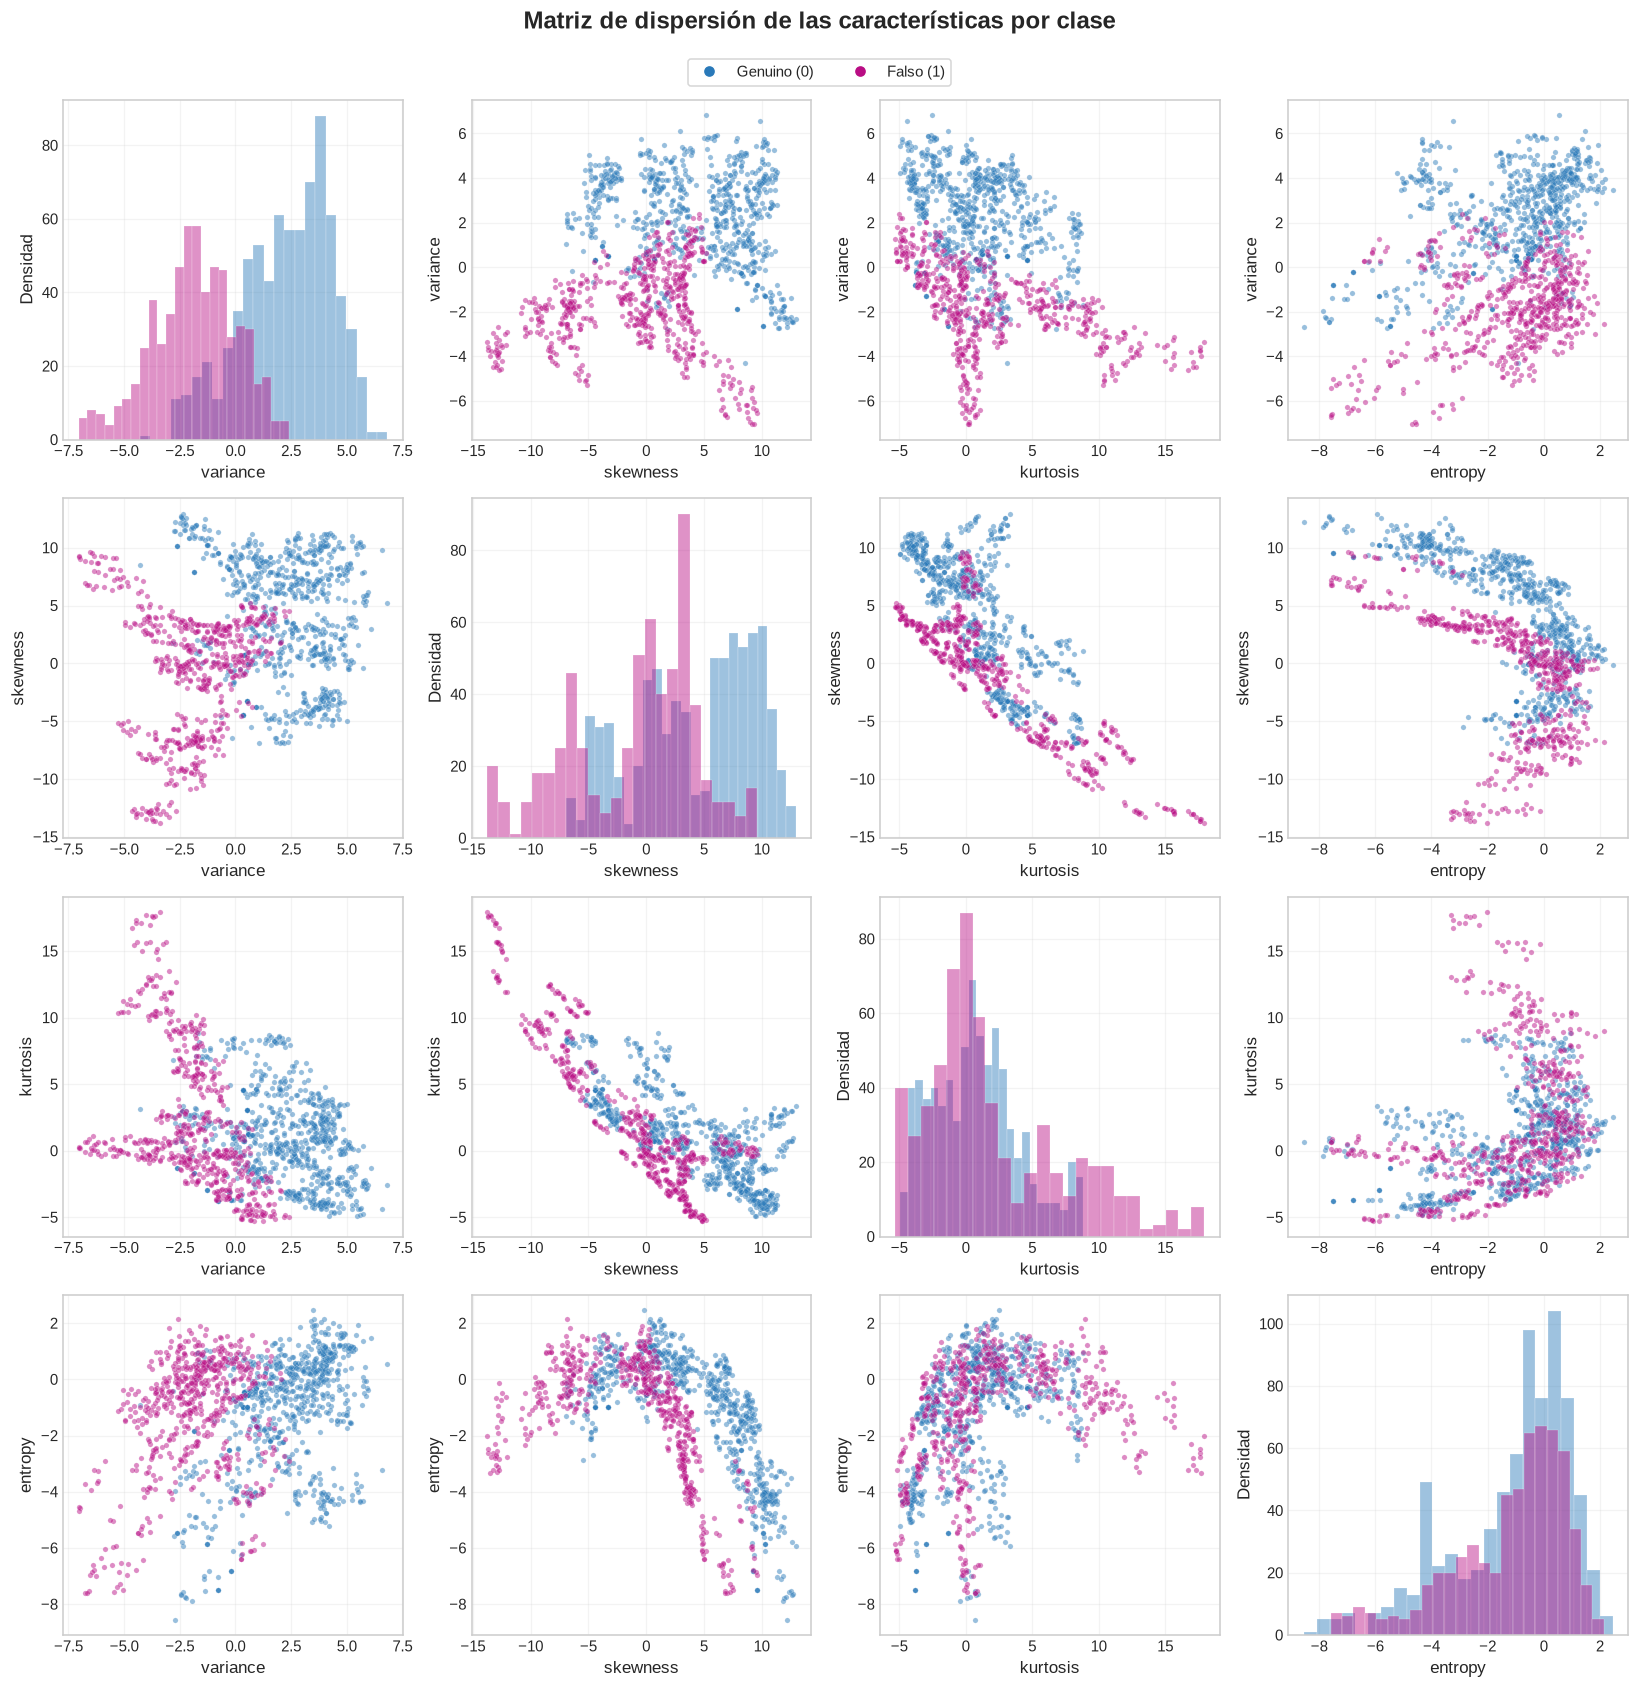

In [129]:
fig, axes = plt.subplots(len(FEATURES), len(FEATURES), figsize=(15, 15))

for row, y_feature in enumerate(FEATURES):
    for col, x_feature in enumerate(FEATURES):
        ax = axes[row, col]
        if row == col:
            # En la diagonal se muestra la distribución univariada de cada característica.
            for label, color in COLORS.items():
                values = df.loc[df[TARGET] == label, x_feature]
                ax.hist(values, bins=24, alpha=0.45, color=color,
                        edgecolor='white', linewidth=0.3, label=CLASS_LABELS[label])
            ax.set_ylabel('Densidad' if col == 0 else '')
        else:
            # Fuera de la diagonal se comparan dos variables y se conserva la clase.
            for label, color in COLORS.items():
                subset = df[df[TARGET] == label]
                ax.scatter(
                    subset[x_feature], subset[y_feature],
                    s=12, alpha=0.48, color=color,
                    edgecolors='white', linewidths=0.2,
                )
        # Cada panel conserva las etiquetas de ambos ejes para poder interpretarlo
        # de forma independiente al exportarlo o recortarlo del notebook.
        ax.set_xlabel(x_feature)
        ax.set_ylabel('Densidad' if row == col else y_feature)
        ax.grid(alpha=0.22)

handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=CLASS_LABELS[label],
               markerfacecolor=color, markersize=8)
    for label, color in COLORS.items()
]
fig.legend(handles=handles, loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 0.995), frameon=True)
fig.suptitle('Matriz de dispersión de las características por clase',
             y=1.02, fontsize=16, fontweight='bold')
fig.tight_layout()
fig.savefig(PLOTS_DIR / '04_matriz_dispersion_por_clase.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.11 Regresión logística: teoría y elección del modelo

La regresión logística es un clasificador discriminativo lineal. Primero calcula una puntuación lineal:

$$z = w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4 + b,$$

luego la convierte en probabilidad mediante la función sigmoide:

$$P(y=1\\mid x) = \\sigma(z) = \\frac{1}{1 + e^{-z}}.$$

Con el umbral usual de `0.5`, predice falso cuando la probabilidad estimada es al menos `0.5`; equivalentemente, cuando `z >= 0`. El entrenamiento minimiza la pérdida logarítmica y, por defecto, usa regularización L2 para evitar coeficientes excesivamente grandes.

## ¿Por qué usarla como modelo base?

- Es adecuada para una etiqueta binaria.
- Es rápida y reproducible en solo cuatro dimensiones.
- Sus coeficientes permiten interpretar la dirección y fuerza relativa de cada característica estandarizada.
- Proporciona una referencia lineal clara antes de comparar con el modelo no lineal de la pareja B.

## ¿Por qué `lbfgs`?

`lbfgs` es un optimizador cuasi-Newton que aproxima la curvatura de la función objetivo usando memoria limitada. Es una elección sólida para problemas pequeños o medianos, con variables continuas, pérdida suave y regularización L2. En este dataset de 1,372 filas y cuatro predictores ofrece una solución estable sin necesitar un algoritmo especializado para datos dispersos.

## ¿Por qué `max_iter=2000`?

`max_iter` es el máximo de iteraciones del optimizador, no el número de observaciones ni de épocas del modelo. Se fija en `2000` como margen de seguridad para que todos los pliegues puedan converger aun cuando una partición sea ligeramente más difícil. No significa que siempre se ejecuten 2000 iteraciones: el optimizador se detiene antes si cumple el criterio de convergencia.

In [130]:
logistic_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='lbfgs',
        max_iter=2_000,
        random_state=RANDOM_STATE,
    )),
])

logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logi

# 1.12 Validación cruzada estratificada de cinco pliegues

## Definición

La validación cruzada estima cómo puede generalizar un modelo a datos no vistos. En lugar de depender de una única partición, divide `X_train` e `y_train` en cinco subconjuntos o **pliegues**.

## Procedimiento paso a paso

1. `StratifiedKFold` construye cinco particiones conservando aproximadamente la misma proporción de billetes falsos y genuinos en cada una.
2. En la iteración 1 se entrenan el escalador y la regresión logística con los pliegues 2–5; el pliegue 1 se usa para validar.
3. En la iteración 2 se repite el proceso dejando el pliegue 2 para validar.
4. Se continúa hasta que cada observación haya sido validación exactamente una vez.
5. Se calcula cada métrica en el pliegue reservado y finalmente se informa la media y la desviación estándar de los cinco resultados.

## ¿Por qué utilizarla?

Una sola partición puede ser afortunada o difícil. La validación cruzada reduce esa dependencia, aprovecha mejor los datos disponibles para estimar el desempeño y muestra la variabilidad entre particiones. La estratificación es importante porque evita que un pliegue tenga una proporción de falsificaciones muy diferente.

El pipeline se clona y ajusta desde cero en cada iteración. Así, `StandardScaler` nunca aprende la media o desviación del pliegue que está validando.

In [131]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision_fake': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall_fake': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1_fake': make_scorer(f1_score, pos_label=1, zero_division=0),
}

cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)

metric_names = list(scoring)
summary = pd.DataFrame({
    'metric': metric_names,
    'mean': [cv_results[f'test_{metric}'].mean() for metric in metric_names],
    'std': [cv_results[f'test_{metric}'].std(ddof=1) for metric in metric_names],
})
summary['result'] = summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1,
)
print('Resumen de validación cruzada (media ± desviación estándar):')
display(summary[['metric', 'result']])

fold_scores = pd.DataFrame({
    metric: cv_results[f'test_{metric}'] for metric in metric_names
}, index=np.arange(1, cv.n_splits + 1))
fold_scores.index.name = 'fold'
print('Resultados de cada pliegue:')
display(fold_scores.round(4))

Resumen de validación cruzada (media ± desviación estándar):


,metric,result
0,accuracy,0.9845 ± 0.0076
1,precision_fake,0.9703 ± 0.0153
2,recall_fake,0.9959 ± 0.0056
3,f1_fake,0.9829 ± 0.0084


Resultados de cada pliegue:


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9773,0.9515,1.0000,0.9751
2,0.9864,0.9798,0.9898,0.9848
3,0.9863,0.9703,1.0000,0.9849
4,0.9772,0.9600,0.9897,0.9746
5,0.9954,0.9898,1.0000,0.9949


# 1.13 Interpretación de los resultados de validación

La **accuracy** es la proporción total de predicciones correctas. La **precision de falsos** responde: de todos los billetes que el modelo marcó como falsos, ¿cuántos eran realmente falsos? El **recall de falsos** responde: de todos los falsos existentes, ¿cuántos detectó? El **F1** es la media armónica de precision y recall, por lo que penaliza que una de ellas sea baja.

La media resume el rendimiento esperado en los pliegues; la desviación estándar refleja cuánto cambia al cambiar la partición. Una desviación pequeña indica resultados estables. El recall de falsos es particularmente relevante operacionalmente porque un falso negativo de esa clase equivale a no detectar una falsificación, aunque la decisión final de costos y umbrales pertenece al análisis integrado.

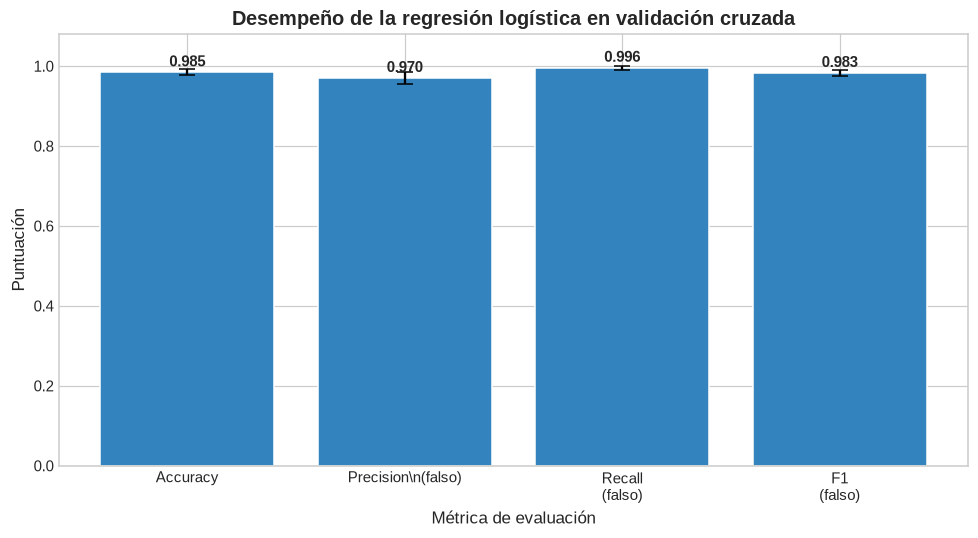

In [135]:
fig, ax = plt.subplots(figsize=(9, 5))
metric_labels = {
    'accuracy': 'Accuracy',
    'precision_fake': 'Precision\\n(falso)',
    'recall_fake': 'Recall\n(falso)',
    'f1_fake': 'F1\n(falso)',
}
means = summary['mean'].to_numpy()
stds = summary['std'].to_numpy()
x = np.arange(len(metric_names))
bars = ax.bar(x, means, yerr=stds, capsize=5, color=blues(0.68), edgecolor='white')
ax.set_xticks(x, [metric_labels[m] for m in metric_names])
ax.set_xlabel('Métrica de evaluación')
ax.set_ylim(0, 1.08)
ax.set_ylabel('Puntuación')
ax.set_title('Desempeño de la regresión logística en validación cruzada')
for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.015, f'{mean:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '05_metricas_validacion_cruzada.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.14 Ajuste final del modelo

La validación cruzada se utiliza para estimar el comportamiento y decidir si la línea base es razonable. Después se ajusta una última instancia del mismo pipeline utilizando **todo `X_train`**. Esto permite que el modelo aproveche todas las observaciones de entrenamiento antes de la futura evaluación en `X_test`.

El conjunto de prueba no participa en el cálculo de medias, desviaciones, coeficientes ni decisiones del modelo. Solo debe utilizarse una vez en la integración final del proyecto, para conservar una estimación honesta sobre datos no usados durante el desarrollo.

In [133]:
logistic_pipeline.fit(X_train, y_train)

model = logistic_pipeline.named_steps['model']
coefficients = pd.Series(model.coef_[0], index=FEATURES)
coefficients = coefficients.sort_values(key=np.abs, ascending=False)

print('Modelo final ajustado sobre X_train.')
print(f'Intercepto: {model.intercept_[0]:.4f}')
print('Coeficientes sobre variables estandarizadas:')
display(coefficients.to_frame('coefficient').round(4))

Modelo final ajustado sobre X_train.
Intercepto: -1.3999
Coeficientes sobre variables estandarizadas:


,coefficient
skewness,-4.8065
variance,-4.6660
kurtosis,-4.3989
entropy,0.2580


# 1.15 ¿Cómo se ve el modelo?

La regresión logística trabaja en cuatro dimensiones, por lo que una frontera completa no puede dibujarse fielmente en un gráfico bidimensional. Para visualizarla se hace una **sección del modelo**:

- se eligen `variance` y `skewness` como ejes;
- se fijan `kurtosis` y `entropy` en sus medianas del entrenamiento;
- se calcula la probabilidad predicha en una rejilla de valores;
- la línea de nivel `0.5` representa la frontera de decisión de esa sección.

Los puntos se muestran en sus valores originales, pero la rejilla se transforma dentro del pipeline antes de predecir. Esta figura no reemplaza la evaluación cuantitativa: muestra cómo el modelo combina linealmente dos variables manteniendo las otras constantes.

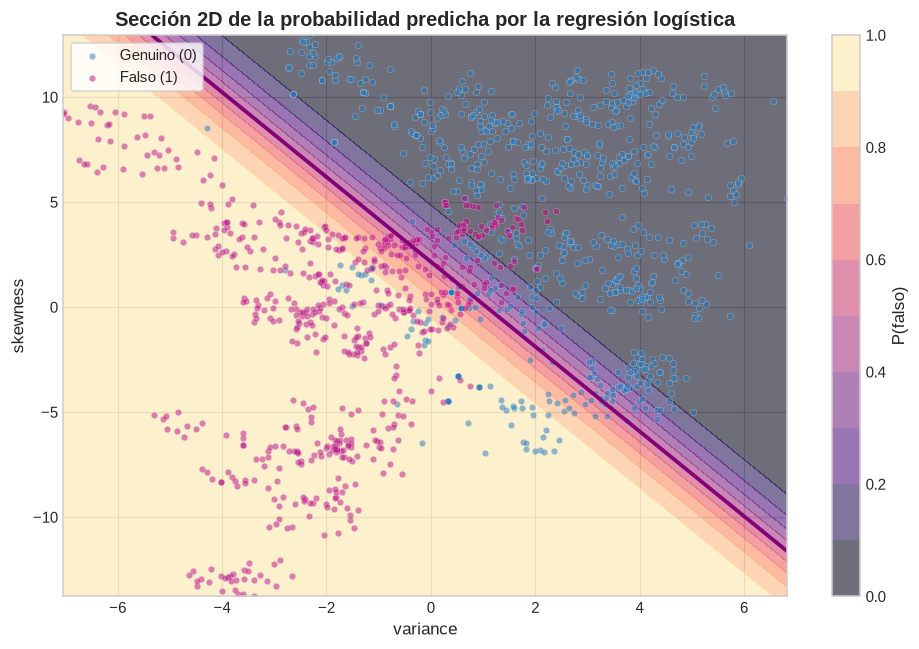

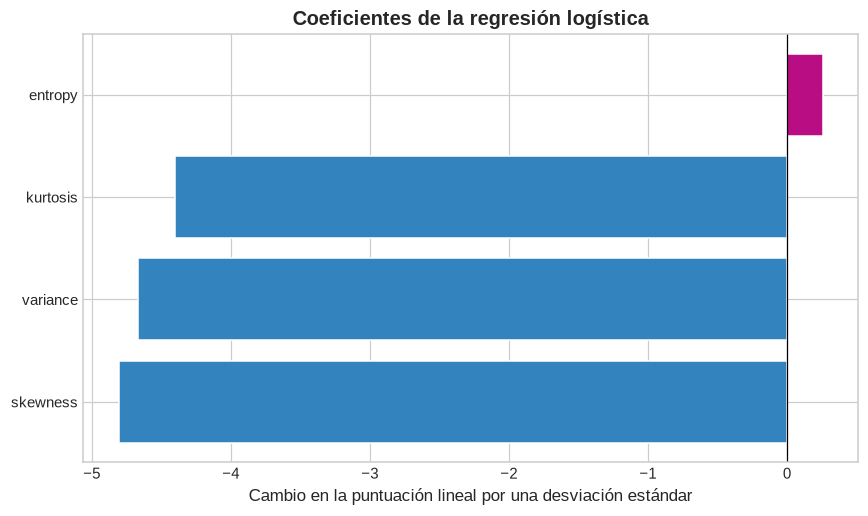

In [134]:
feature_x, feature_y = 'variance', 'skewness'
fixed_features = [feature for feature in FEATURES if feature not in {feature_x, feature_y}]

x_values = np.linspace(X_train[feature_x].min(), X_train[feature_x].max(), 180)
y_values = np.linspace(X_train[feature_y].min(), X_train[feature_y].max(), 180)
xx, yy = np.meshgrid(x_values, y_values)
grid = pd.DataFrame({feature: 0.0 for feature in FEATURES}, index=xx.ravel())
grid[feature_x] = xx.ravel()
grid[feature_y] = yy.ravel()
for feature in fixed_features:
    grid[feature] = X_train[feature].median()
probability = logistic_pipeline.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(9, 6))
levels = np.linspace(0, 1, 11)
contour = ax.contourf(xx, yy, probability, levels=levels, cmap='magma', alpha=0.58)
ax.contour(xx, yy, probability, levels=[0.5], colors=[corals(0.85)], linewidths=2.5)
for label, color in COLORS.items():
    subset = df[df[TARGET] == label]
    ax.scatter(
        subset[feature_x], subset[feature_y], s=18, alpha=0.5,
        color=color, edgecolors='white', linewidths=0.25,
        label=CLASS_LABELS[label],
    )
fig.colorbar(contour, ax=ax, label='P(falso)')
ax.set_xlabel(feature_x)
ax.set_ylabel(feature_y)
ax.set_title('Sección 2D de la probabilidad predicha por la regresión logística')
ax.legend(frameon=True)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '06_superficie_probabilidad_modelo.png', dpi=300, bbox_inches='tight')
plt.show()

# Los coeficientes permiten ver qué dirección favorece la predicción de la clase 1.
fig, ax = plt.subplots(figsize=(8, 4.8))
ordered = coefficients.sort_values()
bar_colors = [blues(0.68) if value < 0 else corals(0.72) for value in ordered]
ax.barh(ordered.index, ordered.values, color=bar_colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Coeficientes de la regresión logística')
ax.set_xlabel('Cambio en la puntuación lineal por una desviación estándar')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '07_coeficientes_regresion_logistica.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.16 Conclusiones detalladas de la pareja A

## Hallazgos del análisis de datos

1. **Calidad y estructura:** el dataset contiene 1,372 billetes descritos por cuatro variables continuas y una etiqueta binaria. No se encontraron valores nulos ni valores no finitos en los predictores. Se detectaron 24 filas duplicadas; se reportan, pero no se eliminan automáticamente porque una fila repetida puede ser una observación válida del conjunto original y eliminarla sin una regla documentada cambiaría la muestra.

2. **Distribución de clases:** hay 762 billetes genuinos (`55.54%`) y 610 falsos (`44.46%`). La diferencia es moderada, no extrema, por lo que el conjunto está razonablemente balanceado. Aun así, se utiliza estratificación para que cada partición conserve una proporción similar y no se depende únicamente de accuracy.

## ¿Por qué se escogieron estas cuatro variables?

3. **Son los predictores definidos por el dataset:** `variance`, `skewness`, `kurtosis` y `entropy` no fueron elegidos arbitrariamente durante este notebook. Son los cuatro descriptores estadísticos de la imagen transformada mediante wavelets que proporciona el conjunto Banknote Authentication. Representan propiedades distintas de la señal visual del billete y condensan información de la imagen en variables numéricas manejables.

4. **Varianza:** aporta información sobre la dispersión de los valores de la imagen transformada. Diferencias en textura, contraste o variabilidad local pueden ayudar a distinguir billetes genuinos de falsificaciones.

5. **Asimetría:** describe si la distribución de intensidades se inclina hacia un lado. Es útil porque dos imágenes pueden tener una dispersión parecida, pero una distribución de intensidades diferente.

6. **Curtosis:** aporta información sobre la concentración central y el peso de las colas de la distribución. Complementa a la varianza y a la asimetría al capturar otra característica de la forma estadística de la imagen.

7. **Entropía:** resume el grado de irregularidad o información presente. Puede capturar diferencias de complejidad visual que no quedan completamente descritas por los momentos anteriores.

8. **Se conservaron las cuatro variables:** el objetivo de la pareja A es establecer una línea base reproducible, no hacer selección de características de manera exploratoria. Usar todos los predictores disponibles evita descartar información antes de medir el modelo. Además, solo hay cuatro variables, por lo que el costo computacional y el riesgo de sobrecargar el modelo son bajos. Una selección posterior debería justificarse con un procedimiento dentro de la validación cruzada para no introducir optimismo ni fuga de información.

9. **Relaciones entre variables:** la correlación asimetría-curtosis es aproximadamente `-0.79` y la de asimetría-entropía aproximadamente `-0.53`. Esto indica que algunos descriptores comparten información lineal, pero no significa que sean duplicados perfectos ni que alguno deba eliminarse automáticamente. La correlación no mide relaciones no lineales ni capacidad predictiva directa.

## Preprocesamiento y modelo

10. **Estandarización:** los predictores tienen rangos y desviaciones diferentes. Se estandarizan para que la optimización y la regularización de la regresión logística trabajen en una escala comparable. El `StandardScaler` está dentro del pipeline y se ajusta desde cero en cada pliegue; por eso las medias y desviaciones del pliegue de validación no influyen en el entrenamiento.

11. **Regresión logística:** se escogió como modelo base porque la etiqueta es binaria, el número de predictores es pequeño y el modelo ofrece probabilidades e interpretabilidad. Su frontera lineal permite establecer una referencia clara antes de valorar si el modelo no lineal de la pareja B captura patrones adicionales. Los coeficientes del ajuste final muestran efectos negativos para variance, skewness y kurtosis, y un efecto positivo menor para entropy; estas direcciones deben interpretarse sobre variables estandarizadas y con cautela debido a la correlación entre predictores. No representan causalidad.

12. **Configuración del optimizador:** `lbfgs` es adecuado para una función objetivo suave, variables continuas y un dataset pequeño. `max_iter=2000` proporciona margen suficiente para que el optimizador converja en cada pliegue; no obliga a ejecutar siempre 2,000 iteraciones, porque se detiene cuando alcanza el criterio de convergencia.

## Evaluación y significado de los resultados

13. **Validación cruzada:** los cinco pliegues generan estimaciones sobre distintas particiones y permiten reportar media y desviación estándar. La media observada del recall de falsos es `0.9959` y su desviación estándar `0.0056`, mientras que el F1 medio es `0.9829 ± 0.0084`. Esto indica un desempeño alto y estable de la línea base en los pliegues, pero no prueba por sí solo que la regresión logística sea mejor que el segundo modelo.

14. **Ajuste final:** después de estimar el desempeño mediante validación cruzada, el pipeline se ajusta con todo `X_train`. `X_test` permanece reservado para la evaluación conjunta final. Esta separación permite que la comparación entre modelos use datos que no guiaron la selección ni el ajuste.

15. **Conclusión del eje A:** la regresión logística constituye una línea base sólida porque utiliza las cuatro variables originales, las escala correctamente, evita fuga de información y se evalúa con un protocolo estratificado. La respuesta a la pregunta global —qué modelo es superior— debe esperar a que el modelo de la pareja B se evalúe con el mismo protocolo y a que la pareja C contraste sus recalls, errores y significancia estadística.

16. **Lectura práctica:** si el modelo lineal ya alcanza un recall muy alto, el modelo no lineal solo justificaría su mayor complejidad si mejora de forma consistente el recall o reduce errores relevantes, y si esa mejora es estadísticamente y operacionalmente importante. Si la mejora es mínima, la simplicidad e interpretabilidad de la regresión logística pueden ser ventajas prácticas.